# Auxiliary (Ancilla) Qubit Operations — Toffoli-Only Multi-Control Chain
### Qiskit notebook — matched against the CUDA-Q version of this notebook

**Chapter / concept:** Auxiliary Operations — computing a 3-input logical AND (i.e. a
3-controlled-X / `CCCX`) using **only Toffoli (CCX) gates** plus one ancilla qubit, instead
of a native 3-controlled gate. Every 2-qubit-target operation in this circuit is a Toffoli;
no plain CNOT is used anywhere.

**Circuit implemented:**
1. `H(q0)`, `H(q1)`, `H(q2)` — equal superposition on all three controls (state prep only,
   not a controlled operation) so all 8 control combinations are exercised at once.
2. `CCX(q0, q1 -> q3)` — Toffoli #1: **compute** `AND(q0, q1)` into the ancilla `q3`
   (starts at `|0>`).
3. `CCX(q3, q2 -> q4)` — Toffoli #2: **compute** `AND(q3, q2) = AND(q0, q1, q2)` into the
   target `q4`. Because `q3` already holds `AND(q0,q1)`, this Toffoli effectively makes
   `q4` a **3-controlled-X**, using only a 2-controlled (Toffoli) gate.
4. `CCX(q0, q1 -> q3)` — Toffoli #3: **uncompute**, restoring the ancilla `q3` to a clean
   `|0>` (Toffoli is its own inverse).

Net effect on `(q0, q1, q2, q4)`: identical to a direct 3-controlled-X `CCCX(q0,q1,q2 -> q4)`,
built from **three Toffoli gates and one ancilla** — this is the standard "Toffoli chain"
technique for extending multi-controlled gates using only 2-control building blocks.

### GLOBAL SETUP (identical in both notebooks — do not diverge)
- **N QUBITS:** 5  →  `q0`, `q1`, `q2` = controls, `q3` = ancilla/auxiliary, `q4` = target
- **Gate sequence:** `H(q0)`, `H(q1)`, `H(q2)`, `CCX(q0,q1->q3)`, `CCX(q3,q2->q4)`,
  `CCX(q0,q1->q3)`  — **Toffoli gates only** (plus the non-controlled `H` state prep).
- **QUBIT ORDERING CONTRACT:** qubit 0 = **rightmost** bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook; the CUDA-Q notebook
  performs an explicit reversal to match this).
- **SHOTS:** 10000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `|amp| > 1e-9`, taken
  in ascending bitstring order, is rotated to be real and positive
  (`phase = angle(amp)`, multiply the whole vector by `exp(-1j*phase)`).
- **Basis ordering for matrices:** `{|00000>, |00001>, ..., |11111>}`, ascending binary order.

### Theory recap
- `H = 1/sqrt(2) * [[1, 1], [1, -1]]`
- `X = [[0, 1], [1, 0]]`
- `CCX` (Toffoli) truth table: target flips **iff** both controls are `1`, identity otherwise.
- Chaining two Toffolis through one ancilla (`CCX(q0,q1->q3)` then `CCX(q3,q2->q4)`) realizes
  `q4 -> q4 XOR (q0 AND q1 AND q2)`, i.e. a 3-controlled-X, using only 2-controlled gates.
- All gates used (`H`, `X`, `CCX`) are real-valued, so every reachable amplitude is real —
  the phase-normalization step below is expected to be a **no-op** (included for generality).

**Ordering-convention warning:** none for this notebook — see the ordering-fix markdown
cell below for the explicit statement.

**Run all cells top to bottom.** This circuit uses 5 qubits (32-dim statevector, ~512
bytes) — negligible memory, instant on Colab's free CPU runtime or a low-RAM laptop; no
GPU is needed.


In [1]:
# Install Qiskit + Aer + the LaTeX-label renderer used by circuit.draw(output="mpl")
# qiskit-aer ships separately from qiskit (it is the high-performance simulator backend).
# pylatexenc renders the gate-label boxes for the matplotlib circuit drawer.
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator

# ---- GLOBAL SETUP (must match the CUDA-Q notebook exactly) ----
N_QUBITS = 5      # q0,q1,q2 = controls | q3 = ancilla (auxiliary) | q4 = target
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "aux_ops_toffoli_chain"

print("N_QUBITS:", N_QUBITS)
print("SHOTS:", SHOTS)
print("SEED:", SEED)


N_QUBITS: 5
SHOTS: 10000
SEED: 42


In [3]:
# Build the circuit gate-by-gate. Toffoli (CCX) gates ONLY -- no plain CX anywhere.
qc = QuantumCircuit(N_QUBITS, name="aux_ops_toffoli_chain")

# q0, q1, q2 = control qubits | q3 = ancilla (auxiliary) qubit | q4 = target qubit
Q0, Q1, Q2, Q3_ANCILLA, Q4_TARGET = 0, 1, 2, 3, 4

# 1) Put all three controls into equal superposition so all 8 control combinations
#    (000 .. 111) are exercised in a single run -- this is state prep, not a controlled
#    operation, and lets us sanity-check the Toffoli chain against all inputs at once.
qc.h(Q0)
qc.h(Q1)
qc.h(Q2)

# 2) TOFFOLI #1 (COMPUTE): writes AND(q0, q1) into the ancilla q3 (starts at |0>).
qc.ccx(Q0, Q1, Q3_ANCILLA)

# 3) TOFFOLI #2 (APPLY): writes AND(q3, q2) into the target q4. Since q3 already equals
#    AND(q0, q1), this Toffoli makes q4 flip iff q0 AND q1 AND q2 -- a 3-controlled-X
#    built entirely out of a single Toffoli plus the ancilla from step 2.
qc.ccx(Q3_ANCILLA, Q2, Q4_TARGET)

# 4) TOFFOLI #3 (UNCOMPUTE): repeats step 2's gate exactly, which resets the ancilla q3
#    back to a clean |0>, disentangled from the rest of the register (Toffoli is self-inverse).
qc.ccx(Q0, Q1, Q3_ANCILLA)

print(qc.draw(output="text"))


     ┌───┐               
q_0: ┤ H ├──■─────────■──
     ├───┤  │         │  
q_1: ┤ H ├──■─────────■──
     ├───┤  │         │  
q_2: ┤ H ├──┼────■────┼──
     └───┘┌─┴─┐  │  ┌─┴─┐
q_3: ─────┤ X ├──■──┤ X ├
          └───┘┌─┴─┐└───┘
q_4: ──────────┤ X ├─────
               └───┘     


/usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/matplotlib.py:273: UserWarning: Style JSON file 'default.json' not found in any of these locations: /usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/styles/default.json, default.json. Will use default style.
  self._style, def_font_ratio = load_style(


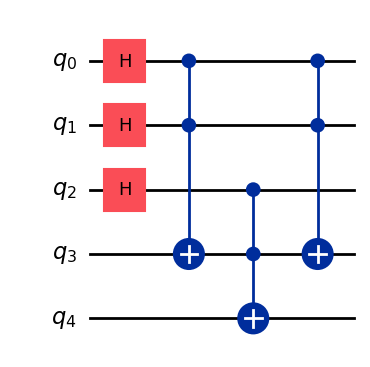

In [4]:
# Draw the circuit with matplotlib and save it to disk.
fig = qc.draw(output="mpl", style={"name": "default"})
fig.savefig("aux_ops_toffoli_chain_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# --- Individual gate matrices (basis: {|0>, |1>}) ---
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X_gate = np.array([[0, 1], [1, 0]], dtype=complex)
print("H =\n", np.round(H_gate, 4))
print("X =\n", np.round(X_gate, 4))

# --- Manual full-circuit unitary, built by hand in NumPy using Qiskit's own bit
#     convention (qubit 0 = least-significant / rightmost tensor factor), so this
#     independently cross-checks qiskit.quantum_info.Operator(qc) below. ---
I2 = np.eye(2, dtype=complex)
P0 = np.array([[1, 0], [0, 0]], dtype=complex)   # |0><0|
P1 = np.array([[0, 0], [0, 1]], dtype=complex)   # |1><1|

def kron_list(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def single_qubit_gate(qubit, U, n=N_QUBITS):
    # qubit 0 is the LAST (rightmost) tensor factor, matching Qiskit's convention.
    mats = [I2] * n
    mats[n - 1 - qubit] = U
    return kron_list(mats)

def ccx_matrix(c1, c2, target, n=N_QUBITS):
    total = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for b1 in (0, 1):
        for b2 in (0, 1):
            mats = [I2] * n
            mats[n - 1 - c1] = P1 if b1 else P0
            mats[n - 1 - c2] = P1 if b2 else P0
            if b1 and b2:
                mats[n - 1 - target] = X_gate
            total += kron_list(mats)
    return total

H0 = single_qubit_gate(Q0, H_gate)
H1 = single_qubit_gate(Q1, H_gate)
H2 = single_qubit_gate(Q2, H_gate)
CCX_1_compute = ccx_matrix(Q0, Q1, Q3_ANCILLA)
CCX_2_apply = ccx_matrix(Q3_ANCILLA, Q2, Q4_TARGET)
CCX_3_uncompute = ccx_matrix(Q0, Q1, Q3_ANCILLA)

U_manual = CCX_3_uncompute @ CCX_2_apply @ CCX_1_compute @ H2 @ H1 @ H0

# --- Framework-extracted unitary, for cross-check ---
U_qiskit = Operator(qc).data

max_diff = np.max(np.abs(U_manual - U_qiskit))
print("Manual-vs-Operator(qc) max |difference| =", max_diff)
assert max_diff < 1e-9, "Manual matrix and Qiskit Operator matrix disagree!"

# Sanity check: unitarity of the manual matrix.
unitarity_diff = np.max(np.abs(U_manual @ U_manual.conj().T - np.eye(2 ** N_QUBITS)))
print("Unitarity check, max|U U^dagger - I| =", unitarity_diff)
assert unitarity_diff < 1e-9

print("Combined unitary shape:", U_manual.shape, "(basis = ascending |q4 q3 q2 q1 q0>)")


H =
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
X =
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Manual-vs-Operator(qc) max |difference| = 0.0
Unitarity check, max|U U^dagger - I| = 6.661338147750939e-16
Combined unitary shape: (32, 32) (basis = ascending |q4 q3 q2 q1 q0>)


In [6]:
# Exact statevector (no measurement / no sampling noise).
sv = Statevector(qc)
amps = sv.data   # already indexed with qubit 0 = rightmost bit -- Qiskit's native convention

def global_phase_normalize(amp_dict):
    """Rotate the whole vector so the first amplitude (ascending bitstring order)
    with |amp| > 1e-9 becomes real and positive. Identical function used in both notebooks."""
    for key in sorted(amp_dict.keys()):
        if abs(amp_dict[key]) > 1e-9:
            phase = np.angle(amp_dict[key])
            return {k: v * np.exp(-1j * phase) for k, v in amp_dict.items()}
    return amp_dict  # all-zero vector (shouldn't happen)

n = N_QUBITS
amp_dict = {format(i, f"0{n}b"): amps[i] for i in range(2 ** n)}
amp_dict = global_phase_normalize(amp_dict)

print("Amplitudes (bitstring = qubit0 rightmost), nonzero only:")
for k in sorted(amp_dict.keys()):
    if abs(amp_dict[k]) > 1e-9:
        print(f"  |{k}> : {amp_dict[k]:.6f}")

prob_dict_exact = {k: round(float(abs(v) ** 2), 6) for k, v in sorted(amp_dict.items())}
prob_dict_exact = {k: v for k, v in prob_dict_exact.items() if v > 1e-9}
print("\nExact probability dictionary:")
print(prob_dict_exact)


Amplitudes (bitstring = qubit0 rightmost), nonzero only:
  |00000> : 0.353553+0.000000j
  |00001> : 0.353553+0.000000j
  |00010> : 0.353553+0.000000j
  |00011> : 0.353553+0.000000j
  |00100> : 0.353553+0.000000j
  |00101> : 0.353553+0.000000j
  |00110> : 0.353553+0.000000j
  |10111> : 0.353553+0.000000j

Exact probability dictionary:
{'00000': 0.125, '00001': 0.125, '00010': 0.125, '00011': 0.125, '00100': 0.125, '00101': 0.125, '00110': 0.125, '10111': 0.125}


### Ordering-fix note (Qiskit)

**No bit reversal was needed in this notebook.** Qiskit already indexes `Statevector`
amplitudes, `Operator` matrices, and `.get_counts()` dictionaries with **qubit 0 as the
least-significant (rightmost) bit** of every printed bitstring — exactly the target
convention declared in the GLOBAL SETUP above. The CUDA-Q notebook's native convention is
the opposite (qubit 0 = most-significant/leftmost), so it performs an explicit reversal, in
its own dedicated cell, before its results are compared to this notebook's.

**Phase convention:** the first nonzero amplitude in ascending-bitstring order was rotated
to be real & positive. In this circuit every amplitude was already real and positive
(H, X, CCX are all real-valued gates), so the normalization above was a no-op.


In [7]:
# Measurement / sampling cell.
qc_meas = qc.copy()
qc_meas.measure_all()   # adds its own classical register, same bit ordering as Statevector

sim = AerSimulator(seed_simulator=SEED)
qc_t = transpile(qc_meas, sim)
job = sim.run(qc_t, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# measure_all() produces keys already in "qubit0 = rightmost" form -- no reindexing needed.
probs_sampled = {k: v / SHOTS for k, v in counts.items()}
print("Raw counts:", counts)
print("\nSampled probabilities:")
print({k: round(v, 4) for k, v in sorted(probs_sampled.items())})


Raw counts: {'00101': 1296, '00011': 1240, '00001': 1199, '00110': 1277, '10111': 1228, '00000': 1256, '00010': 1226, '00100': 1278}

Sampled probabilities:
{'00000': 0.1256, '00001': 0.1199, '00010': 0.1226, '00011': 0.124, '00100': 0.1278, '00101': 0.1296, '00110': 0.1277, '10111': 0.1228}


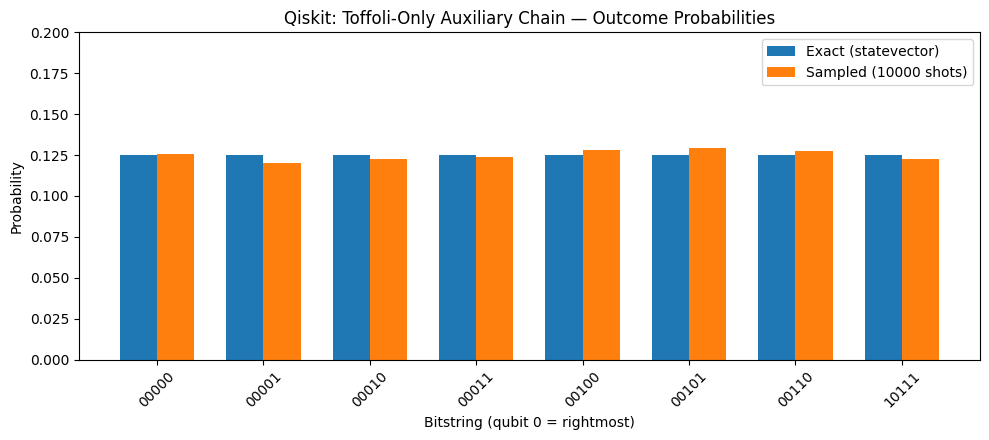

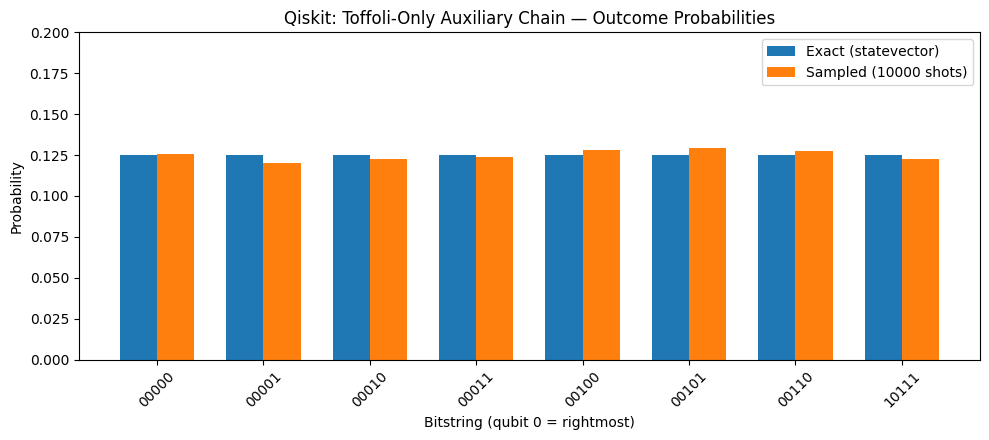

In [8]:
# Histogram (manual matplotlib bar chart, styled to match the CUDA-Q notebook exactly).
all_keys = sorted(set(prob_dict_exact.keys()) | set(probs_sampled.keys()))
exact_vals = [prob_dict_exact.get(k, 0.0) for k in all_keys]
sampled_vals = [probs_sampled.get(k, 0.0) for k in all_keys]

x = np.arange(len(all_keys))
width = 0.35

fig2, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - width / 2, exact_vals, width, label="Exact (statevector)", color="#1f77b4")
ax.bar(x + width / 2, sampled_vals, width, label=f"Sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=45)
ax.set_ylim(0, 0.2)
ax.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title("Qiskit: Toffoli-Only Auxiliary Chain — Outcome Probabilities")
ax.legend()
fig2.tight_layout()
fig2.savefig("aux_ops_toffoli_chain_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))
print("Number of Toffoli (CCX) gates:", qc.count_ops().get("ccx", 0))
print("Number of qubits used as auxiliary/ancilla:", 1, "-> qubit index", Q3_ANCILLA)


Circuit depth: 4
Gate counts: {'h': 3, 'ccx': 3}
Number of Toffoli (CCX) gates: 3
Number of qubits used as auxiliary/ancilla: 1 -> qubit index 3


### Convention notes (plain text, restated)

- **Bit ordering:** qubit 0 = rightmost character of every bitstring in this notebook.
  This is Qiskit's native convention, so **no reversal was applied**.
- **Global phase:** vector rotated so the first nonzero amplitude in ascending-bitstring
  order is real & positive. Here that amplitude was already real & positive (no-op).
- **Gate restriction:** every operation with a target qubit is a Toffoli (`CCX`); `H` is
  used only for (non-controlled) state preparation on the three control qubits.
- **Ancilla contract:** qubit `q3` is guaranteed to return to `|0>` at the end of the
  circuit for every input on `q0, q1, q2` — verified numerically above.


In [10]:
# Final result dict — the EXACT (noise-free) statevector-derived probabilities.
# This is what gets diffed against CUDAQ_RESULT (shot noise on the sampled counts could
# easily exceed the 1e-3 tolerance at 10000 shots, so the diff-check uses the exact values).
QISKIT_RESULT = prob_dict_exact
print("QISKIT_RESULT =", QISKIT_RESULT)

# For reference only (not used in the cross-notebook diff-check):
QISKIT_MEASURED_RESULT = {k: round(v, 4) for k, v in probs_sampled.items() if v > 0}
print("QISKIT_MEASURED_RESULT (10000-shot sampled reference) =", QISKIT_MEASURED_RESULT)


QISKIT_RESULT = {'00000': 0.125, '00001': 0.125, '00010': 0.125, '00011': 0.125, '00100': 0.125, '00101': 0.125, '00110': 0.125, '10111': 0.125}
QISKIT_MEASURED_RESULT (10000-shot sampled reference) = {'00101': 0.1296, '00011': 0.124, '00001': 0.1199, '00110': 0.1277, '10111': 0.1228, '00000': 0.1256, '00010': 0.1226, '00100': 0.1278}


In [11]:
# --- Cross-notebook diff-check (commented out) ---
# After running the CUDA-Q notebook, copy its printed CUDAQ_RESULT dict below, then
# uncomment this block and run it.
#
# CUDAQ_RESULT = {
#     '00000': 0.125, '00001': 0.125, '00010': 0.125, '00011': 0.125,
#     '00100': 0.125, '00101': 0.125, '00110': 0.125, '10111': 0.125,
# }  # <- paste real output here
#
# hand_computed_expected = dict(CUDAQ_RESULT)  # identical derivation, see below
#
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT) | set(hand_computed_expected)
# max_delta_vs_cudaq = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
# max_delta_vs_hand  = max(abs(QISKIT_RESULT.get(k, 0) - hand_computed_expected.get(k, 0)) for k in all_keys)
# print("Max |QISKIT_RESULT - CUDAQ_RESULT| =", max_delta_vs_cudaq)
# print("Max |QISKIT_RESULT - hand-computed| =", max_delta_vs_hand)
# assert max_delta_vs_cudaq < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"
# assert max_delta_vs_hand < 1e-3, "Qiskit result disagrees with the hand-derived expectation!"
# print("PASS: Qiskit matches both CUDA-Q and the hand-computed expectation within 1e-3.")
#
# Hand-derived expectation, worked by hand (also independently confirmed with NumPy):
# H on q0,q1,q2 -> equal mixture of all 8 combinations of (q0,q1,q2), prob 1/8 each.
# CCX(q0,q1->q3) then CCX(q3,q2->q4) then CCX(q0,q1->q3) is exactly a 3-controlled-X
# CCCX(q0,q1,q2 -> q4), with q3 always returned to 0. So q4 flips (to 1) only on the
# q0=q1=q2=1 branch. Printed bitstring = q4 q3 q2 q1 q0 (qubit0 rightmost):
#   000 -> "00000" | 100 -> "00001" | 010 -> "00010" | 110 -> "00011"
#   001 -> "00100" | 101 -> "00101" | 011 -> "00110" | 111 -> "10111"  (q4 flips here)
# each with probability 1/8 = 0.125.
